# Categorical Data Analysis
Categorical data analysis is the process of examining variables that represent groups, labels, or categories rather than numerical measurements. It helps us understand which categories exist, how frequently they occur, and how they relate to other variables or a target.

## Unique Categories
Definition
Unique categories are the distinct values present in a categorical variable, without counting repeated values more than once. Identifying them helps us understand what labels exist and detect unexpected or inconsistent entries.
### Real-world example
- Identify the distinct blood groups in a medical dataset.
- Find all unique cities represented in a population survey.
### Business example
- List all payment methods used by customers.
- Identify the product categories available in an e-commerce dataset.
### AI/ML use case
Knowing unique categories helps determine how a categorical feature should be encoded, whether unexpected labels exist, and whether new categories may appear when a model is used in production.

In [2]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.949 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [3]:
import pandas as pd

df = pd.DataFrame({
    "Department": [
        "IT", "HR", "Sales", "IT", "Finance", "HR"
    ]
})

print("Unique categories:")
print(df["Department"].unique())

print("\nNumber of unique categories:")
print(df["Department"].nunique())

Unique categories:
<StringArray>
['IT', 'HR', 'Sales', 'Finance']
Length: 4, dtype: str

Number of unique categories:
4


### Explanation of the code
- unique() returns the distinct department names.
- nunique() counts the number of distinct categories.
- Although the dataset contains six rows, it has only four unique departments.
- These methods help identify the possible values that a categorical feature can take.

## Category Frequencies
Definition
Category frequency refers to the number of times each category appears in a categorical variable. It helps identify the most common and least common categories in a dataset.
### Real-world example
- Count how many students prefer Mathematics, Science, or English.
- Count the number of people using different transportation methods, such as buses, bikes, and cars.
### Business example
- Count the number of orders paid through UPI, Cash, or Card.
- Identify which product categories generate the highest number of orders.
### AI/ML use case
Category frequencies help identify rare categories, detect data-quality issues, and understand whether categorical features are dominated by a small number of values.

In [4]:
import pandas as pd

df = pd.DataFrame({
    "Product": [
        "Laptop", "Mobile", "Laptop",
        "Tablet", "Mobile", "Laptop",
        "Mobile", "Laptop"
    ]
})

print(df["Product"].value_counts())

Product
Laptop    4
Mobile    3
Tablet    1
Name: count, dtype: int64


### Explanation of the code
- value_counts() counts the occurrences of each product category.
- Laptop appears four times, Mobile appears three times, and Tablet appears once.
- By default, categories are sorted from most frequent to least frequent.
- The result helps identify common and uncommon categories.

## Category Distribution
Definition
Category distribution describes how observations are divided among the different categories of a variable. It can be expressed using counts or percentages to show the proportion represented by each category.
### Real-world example
- Calculate the percentage of students who prefer different subjects.
- Analyze the proportion of people who use different payment methods.
### Business example
- Calculate the percentage of customers using UPI, Cash, Card, and Net Banking.
- Examine the distribution of orders across product categories to identify popular product groups.
### AI/ML use case
Category distribution helps determine whether a feature is dominated by particular categories and whether a classification target has an imbalanced class distribution.

In [5]:
import pandas as pd

df = pd.DataFrame({
    "Payment": [
        "UPI", "Cash", "UPI", "Card",
        "UPI", "Cash", "Card", "UPI"
    ]
})

counts = df["Payment"].value_counts()
percentages = df["Payment"].value_counts(normalize=True) * 100

print("Counts:")
print(counts)

print("\nPercentages:")
print(percentages.round(2))

Counts:
Payment
UPI     4
Cash    2
Card    2
Name: count, dtype: int64

Percentages:
Payment
UPI     50.0
Cash    25.0
Card    25.0
Name: proportion, dtype: float64


### Explanation of the code
- value_counts() calculates the number of observations in each category.
- normalize=True converts counts into proportions.
- Multiplying by 100 converts proportions into percentages.
- UPI represents 50% of the observations, while Cash and Card each represent 25%.
- Percentages are particularly useful when comparing datasets with different numbers of observations.

## Rare Categories
Definition
Rare categories are categories that occur infrequently compared with the other categories in a variable. They may represent unusual but meaningful cases, data-entry errors, or categories that need special treatment before modeling.
### Real-world example
- Only a few students in a school choose a particular optional subject.
- Only a small number of people in a survey report a particular occupation.
### Business example
- An online store receives only a few orders for a particular product type.
- A company has very few customers using an uncommon payment method.
### AI/ML use case
Rare categories can produce unreliable estimates or create many sparse features after encoding. Data scientists may group rare categories into an Other category when appropriate, while preserving important categories that have business significance.

In [6]:
import pandas as pd

df = pd.DataFrame({
    "Product": [
        "Mobile", "Laptop", "Mobile", "Tablet",
        "Mobile", "Laptop", "Camera", "Mobile"
    ]
})

counts = df["Product"].value_counts()
rare = counts[counts < 2]

print("Rare categories:")
print(rare)

Rare categories:
Product
Tablet    1
Camera    1
Name: count, dtype: int64


### Explanation of the code
- value_counts() calculates the frequency of each product.
- counts < 2 identifies categories appearing fewer than two times.
- Tablet and Camera are flagged as rare categories.
- The threshold of two is chosen for this learning example; real projects should use thresholds appropriate to dataset size and business requirements.

## High Cardinality
Definition
High cardinality occurs when a categorical variable contains a large number of distinct categories. Examples include customer IDs, product IDs, email addresses, and postal codes.
### Real-world example
- A dataset contains thousands of different residential postal codes.
- A hospital database contains thousands of unique patient identifiers.
### Business example
- An e-commerce company has hundreds of thousands of distinct product IDs.
- A customer database contains a separate customer identifier for every customer.
### AI/ML use case
High-cardinality features can create very large one-hot encoded datasets, increase memory usage, and lead to overfitting. Depending on the problem, techniques such as frequency encoding, carefully designed target encoding, feature hashing, or embeddings may be useful.

In [7]:
import pandas as pd

df = pd.DataFrame({
    "Customer_ID": [
        "C101", "C102", "C103", "C104",
        "C105", "C106", "C107", "C108"
    ]
})

print("Total rows:", len(df))
print("Unique customers:", df["Customer_ID"].nunique())

Total rows: 8
Unique customers: 8


### Explanation of the code
- len(df) returns the number of rows.
- nunique() counts the distinct customer IDs.
- Every row contains a different ID, so cardinality equals the number of observations.
- In a large dataset, such a feature can create many encoded columns if one-hot encoding is used.
- Customer IDs are often identifiers rather than meaningful predictive features, so they should be evaluated carefully before modeling.

## Low Cardinality
Definition
Low cardinality occurs when a categorical variable contains only a small number of distinct categories. These variables are often straightforward to summarize and encode.
### Real-world example
- A person answers a survey question with Yes, No, or Maybe.
- A traffic signal has three categories: Red, Yellow, and Green.
### Business example
- An order has one of three statuses: Pending, Shipped, or Delivered.
- A customer belongs to one of three membership tiers: Bronze, Silver, or Gold.
### AI/ML use case
Low-cardinality features are often suitable for one-hot encoding or ordinal encoding when the categories have a genuine order. Their small number of categories makes them relatively easy to inspect and manage.

In [8]:
import pandas as pd

df = pd.DataFrame({
    "Order_Status": [
        "Pending", "Shipped", "Delivered",
        "Delivered", "Shipped", "Delivered"
    ]
})

print("Unique categories:",
      df["Order_Status"].unique())

print("Cardinality:",
      df["Order_Status"].nunique())

Unique categories: <StringArray>
['Pending', 'Shipped', 'Delivered']
Length: 3, dtype: str
Cardinality: 3


### Explanation of the code
- unique() lists the distinct order statuses.
- nunique() calculates the cardinality of the feature.
- The variable has three categories, making it a low-cardinality feature in this example.
- The distinction between high and low cardinality depends on the dataset and modeling task; there is no universal cutoff.

## Category Imbalance
Definition
Category imbalance occurs when some categories contain substantially more observations than others. When this happens in a target variable, a Machine Learning classification model may favor the majority class and perform poorly on minority classes.
### Real-world example
- In a school survey, 95% of students choose one option while only 5% choose another.
- In a medical dataset, most people may not have a particular rare condition.
### Business example
- Most customer transactions are legitimate, while only a small proportion are fraudulent.
- Most customers remain subscribed, while a small percentage cancel their subscriptions.
### AI/ML use case
Class imbalance can make accuracy misleading and reduce a model's ability to identify minority cases. Depending on the problem, techniques such as class weights, appropriate resampling, and evaluation using precision, recall, F1-score, and PR-AUC may help.

In [9]:
import pandas as pd

df = pd.DataFrame({
    "Churn": [
        "No", "No", "No", "No", "No",
        "No", "No", "No", "No", "Yes"
    ]
})

print(df["Churn"].value_counts())

print("\nPercentages:")
print(
    (df["Churn"].value_counts(normalize=True) * 100)
    .round(2)
)

Churn
No     9
Yes    1
Name: count, dtype: int64

Percentages:
Churn
No     90.0
Yes    10.0
Name: proportion, dtype: float64


### Explanation of the code
- value_counts() counts customers in each churn category.
- normalize=True calculates the proportion of each category.
- The dataset contains 90% non-churn cases and 10% churn cases.
- This is an imbalanced target because the two classes have different frequencies.
- A model that always predicts No would achieve 90% accuracy on this tiny dataset while failing to identify any churn cases.
- In practice, evaluate minority-class recall and precision as well as overall performance.

## Relationships Between Categorical Variables and the Target
When a dataset has a target variable, categorical analysis can help identify which categories are associated with different target outcomes.

For example, a business may want to understand whether Payment Method is associated with Purchase Status, or whether Contract Type is associated with Customer Churn.
### A. Categorical feature vs categorical target
Definition
This analysis compares a categorical input feature with a categorical target to understand whether the targets distribution differs across the feature's categories.
### Real-world example
- Study whether students' preferred learning methods are associated with pass or fail outcomes.
- Analyze whether different transportation methods are associated with arriving late or on time.
### Business example
- Compare customer churn across monthly and yearly subscription plans.
- Examine whether purchase completion differs across payment methods.
### AI/ML use case
This analysis helps identify potentially informative features for classification tasks, such as churn prediction, fraud detection, and purchase prediction. Association alone does not prove that a feature causes the outcome.

In [10]:
import pandas as pd

df = pd.DataFrame({
    "Contract": [
        "Monthly", "Monthly", "Monthly",
        "Yearly", "Yearly", "Yearly"
    ],
    "Churn": [
        "Yes", "Yes", "No",
        "No", "No", "No"
    ]
})

print(pd.crosstab(df["Contract"], df["Churn"]))

print("\nChurn rate by contract:")
print(
    (pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100).round(2)
)

Churn     No  Yes
Contract         
Monthly    1    2
Yearly     3    0

Churn rate by contract:
Contract
Monthly    66.67
Yearly      0.00
Name: Yes, dtype: float64


### Explanation of the code
- pd.crosstab() counts churn outcomes for each contract type.
- normalize="index" calculates proportions within each contract category.
- Selecting ["Yes"] extracts the proportion of customers who churned.
- Multiplying by 100 expresses churn as a percentage.
- In this small sample, monthly contracts have a higher observed churn rate than yearly contracts.
- A larger, representative dataset is needed before drawing reliable business conclusions.

### B. Visualizing category relationships
Definition
A categorical relationship chart displays how counts or proportions of one categorical variable vary across the categories of another variable. Grouped or stacked bar charts are commonly used.
### Real-world example
- Compare pass and fail counts across different classrooms.
- Compare travel preferences across different age groups.
### Business example
- Compare churned and retained customers across subscription plans.
- Compare completed and cancelled orders across payment methods.
### AI/ML use case
Visualizing categorical relationships helps identify potentially predictive features, imbalanced outcomes, and segments that may require closer investigation.

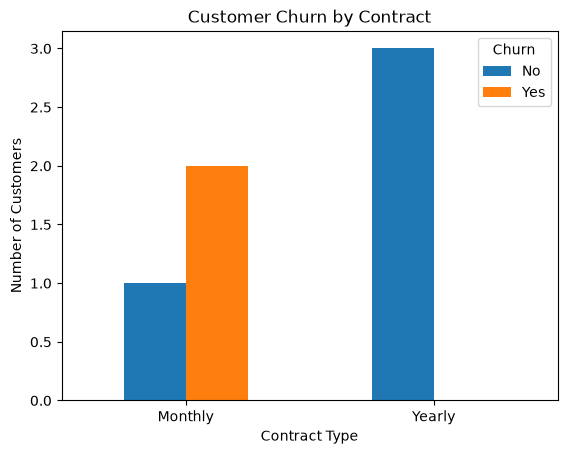

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Contract": [
        "Monthly", "Monthly", "Monthly",
        "Yearly", "Yearly", "Yearly"
    ],
    "Churn": [
        "Yes", "Yes", "No",
        "No", "No", "No"
    ]
})

table = pd.crosstab(df["Contract"], df["Churn"])

table.plot(kind="bar")
plt.title("Customer Churn by Contract")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

### Explanation of the code
- pd.crosstab() creates a table of contract types and churn outcomes.
- plot(kind="bar") draws grouped bars for the target categories.
- xlabel() and ylabel() label the axes.
- plt.show() displays the chart.
- The chart makes it easy to compare customer outcomes across contract categories.